In [1]:
# ASTRAQUANT - Data Exploration

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("ASTRAQUANT ML Environment Ready!")

ModuleNotFoundError: No module named 'seaborn'

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


c:\Users\niyat\AppData\Local\spyder-6\envs\spyder-runtime\python.exe: No module named pip


In [1]:
# ASTRAQUANT - Data Exploration

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("ASTRAQUANT ML Environment Ready!")

ASTRAQUANT ML Environment Ready!


In [2]:
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Environment setup complete!")

Pandas: 3.1.1
NumPy: 2.5.4
Environment setup complete!


In [1]:
import json
import pandas as pd

# Load Bitcoin funding data
with open("../data/bitcoin_funding.json", "r") as file:
    data = json.load(file)

# Convert JSON into a DataFrame
df = pd.DataFrame(data)

# Display the first 5 records
df.head()


FileNotFoundError: [Errno 2] No such file or directory: '../data/bitcoin_funding.json'

In [2]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("\nFiles in this folder:")
print(list(Path.cwd().iterdir()))

Current folder: c:\Users\niyat\ASTRAQUANT

Files in this folder:
[WindowsPath('c:/Users/niyat/ASTRAQUANT/01_data_exploration.ipynb'), WindowsPath('c:/Users/niyat/ASTRAQUANT/data'), WindowsPath('c:/Users/niyat/ASTRAQUANT/models'), WindowsPath('c:/Users/niyat/ASTRAQUANT/notebooks')]


In [3]:
import json
import pandas as pd

with open("data/bitcoin_funding.json", "r") as file:
    data = json.load(file)

df = pd.DataFrame(data)

df.head()


JSONDecodeError: Expecting value: line 2 column 1 (char 1)

In [4]:
with open("data/bitcoin_funding.json", "r") as file:
    content = file.read()

print(repr(content[:500]))

"\nContinued from\nPrepare While Waiting\nyep done can we go to the actual code now\nAbsolutely. We've finished the setup. Let's start writing actual Python code for ASTRAQUANT.\n\nOne important thing: we don't have Person A's dataset yet, so we can't train the real model or decide its target labels. But we can start building the actual data-processing pipeline now.\n\nStep 9: Check for our dataset\nOpen 01_data_exploration.ipynb.\n\nClick + Code and paste this:\n\nfrom pathlib import Path\n\n# Find the ASTRAQU"


In [5]:
import json
import pandas as pd

# Load the Bitcoin dataset
with open("data/bitcoin_funding.json", "r", encoding="utf-8") as file:
    data = json.load(file)

# Convert into a DataFrame
df = pd.DataFrame(data)

# Check the dataset
print("Dataset loaded successfully!")
print("Total records:", len(df))
print("\nColumns:", df.columns.tolist())

# Display first 5 records
display(df.head())

Dataset loaded successfully!
Total records: 500

Columns: ['symbol', 'fundingTime', 'fundingRate', 'markPrice', 'rateType']


,symbol,fundingTime,fundingRate,markPrice,rateType
0,BTCUSDT,1780156800000,0.00006214,73892.79565217,Regular
1,BTCUSDT,1780185600000,0.00004432,73856.90000000,Regular
2,BTCUSDT,1780214400000,0.00005663,73833.30000000,Regular
3,BTCUSDT,1780243200004,0.00005988,73613.40000000,Regular
4,BTCUSDT,1780272000001,0.00005703,73653.56663043,Regular


In [6]:
# Check the structure of our dataset
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nBasic statistics:")
display(df.describe())

Dataset shape: (500, 5)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   symbol       500 non-null    str  
 1   fundingTime  500 non-null    int64
 2   fundingRate  500 non-null    str  
 3   markPrice    500 non-null    str  
 4   rateType     500 non-null    str  
dtypes: int64(1), str(4)
memory usage: 19.7 KB

Missing values:
symbol         0
fundingTime    0
fundingRate    0
markPrice      0
rateType       0
dtype: int64

Basic statistics:


,fundingTime
count,5.000000e+02
mean,1.787342e+12
std,4.161077e+09
min,1.780157e+12
25%,1.783750e+12
50%,1.787342e+12
75%,1.790935e+12
max,1.794528e+12


In [7]:
# Convert text columns into numerical columns
df["fundingRate"] = pd.to_numeric(df["fundingRate"])
df["markPrice"] = pd.to_numeric(df["markPrice"])

# Convert fundingTime from milliseconds into readable dates
df["fundingTime"] = pd.to_datetime(df["fundingTime"], unit="ms")

# Check the changes
print(df.dtypes)

display(df.head())

symbol                    str
fundingTime    datetime64[us]
fundingRate           float64
markPrice             float64
rateType                  str
dtype: object


,symbol,fundingTime,fundingRate,markPrice,rateType
0,BTCUSDT,2026-05-30 16:00:00.000,0.000062,73892.795652,Regular
1,BTCUSDT,2026-05-31 00:00:00.000,0.000044,73856.900000,Regular
2,BTCUSDT,2026-05-31 08:00:00.000,0.000057,73833.300000,Regular
3,BTCUSDT,2026-05-31 16:00:00.004,0.000060,73613.400000,Regular
4,BTCUSDT,2026-06-01 00:00:00.001,0.000057,73653.566630,Regular


In [8]:
# Sort data by time
df = df.sort_values("fundingTime").reset_index(drop=True)

# Check the date range
print("Start date:", df["fundingTime"].min())
print("End date:", df["fundingTime"].max())

# Check time intervals between records
print("\nTime difference between records:")
print(df["fundingTime"].diff().value_counts().head())

# Display first and last records
print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

Start date: 2026-05-30 16:00:00
End date: 2026-11-13 00:00:00

Time difference between records:
fundingTime
0 days 08:00:00.000000    172
0 days 08:00:00.001000     55
0 days 07:59:59.999000     52
0 days 07:59:59.998000     42
0 days 08:00:00.002000     30
Name: count, dtype: int64

First 5 records:


,symbol,fundingTime,fundingRate,markPrice,rateType
0,BTCUSDT,2026-05-30 16:00:00.000,0.000062,73892.795652,Regular
1,BTCUSDT,2026-05-31 00:00:00.000,0.000044,73856.900000,Regular
2,BTCUSDT,2026-05-31 08:00:00.000,0.000057,73833.300000,Regular
3,BTCUSDT,2026-05-31 16:00:00.004,0.000060,73613.400000,Regular
4,BTCUSDT,2026-06-01 00:00:00.001,0.000057,73653.566630,Regular



Last 5 records:


,symbol,fundingTime,fundingRate,markPrice,rateType
495,BTCUSDT,2026-11-11 16:00:00.000,0.000066,73953.100142,Regular
496,BTCUSDT,2026-11-12 00:00:00.000,0.000035,73979.900000,Regular
497,BTCUSDT,2026-11-12 08:00:00.001,0.000062,73622.852924,Regular
498,BTCUSDT,2026-11-12 16:00:00.003,0.000089,71690.510471,Regular
499,BTCUSDT,2026-11-13 00:00:00.000,0.000100,71432.985167,Regular


In [9]:
# Check for duplicate timestamps
duplicates = df["fundingTime"].duplicated().sum()

print("Duplicate timestamps:", duplicates)

# Check the number of unique funding times
print("Unique timestamps:", df["fundingTime"].nunique())

# Check whether timestamps are in chronological order
print(
    "Chronologically sorted:",
    df["fundingTime"].is_monotonic_increasing
)

Duplicate timestamps: 0
Unique timestamps: 500
Chronologically sorted: True


In [10]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["fundingTime"],
    df["fundingRate"]
)

plt.title("Bitcoin Funding Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Funding Rate")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [11]:
import matplotlib.pyplot as plt

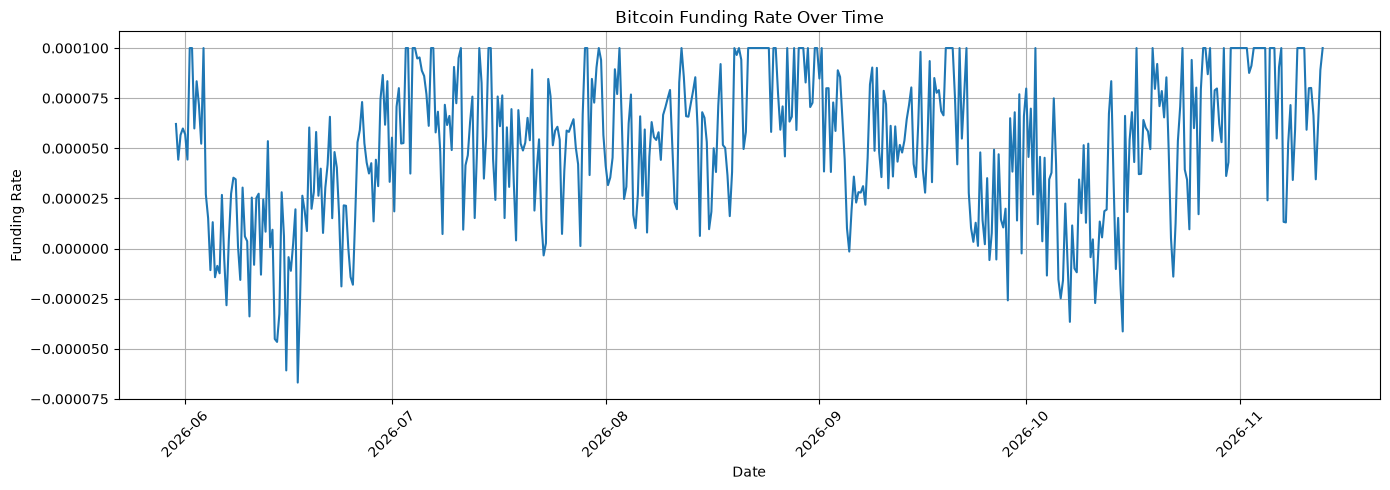

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["fundingTime"],
    df["fundingRate"]
)

plt.title("Bitcoin Funding Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Funding Rate")
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Check funding rate distribution
print("Highest funding rate:", df["fundingRate"].max())
print("Lowest funding rate:", df["fundingRate"].min())
print("Average funding rate:", df["fundingRate"].mean())

# Count records above our proposed spike threshold
threshold = 0.0005

spikes = (df["fundingRate"] > threshold).sum()

print("\nRecords above spike threshold:", spikes)
print("Total records:", len(df))

Highest funding rate: 0.0001
Lowest funding rate: -6.685e-05
Average funding rate: 5.126994e-05

Records above spike threshold: 0
Total records: 500


In [14]:
print("Funding rate percentiles:")

display(
    df["fundingRate"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
    )
)


Funding rate percentiles:


0.50    0.000054
0.75    0.000080
0.90    0.000100
0.95    0.000100
0.99    0.000100
1.00    0.000100
Name: fundingRate, dtype: float64

In [15]:
print("Unique funding rates:", df["fundingRate"].nunique())

print("\nMost common funding rates:")
display(df["fundingRate"].value_counts().head(10))

print("\nFunding rate range:")
print(df["fundingRate"].min(), "to", df["fundingRate"].max())

Unique funding rates: 417

Most common funding rates:


fundingRate
0.000100    78
0.000058     2
0.000083     2
0.000090     2
0.000046     2
0.000072     2
0.000013     2
0.000062     1
0.000044     1
0.000057     1
Name: count, dtype: int64


Funding rate range:
-6.685e-05 to 0.0001


In [16]:
# Count records at the maximum funding rate
max_rate = df["fundingRate"].max()

max_records = df[df["fundingRate"] == max_rate]

print("Maximum funding rate:", max_rate)
print("Records at maximum:", len(max_records))

print("\nRate types:")
print(df["rateType"].value_counts())

print("\nRecords at maximum:")
display(max_records[["fundingTime", "fundingRate", "markPrice", "rateType"]])

Maximum funding rate: 0.0001
Records at maximum: 78

Rate types:
rateType
Regular    500
Name: count, dtype: int64

Records at maximum:


,fundingTime,fundingRate,markPrice,rateType
6,2026-06-01 16:00:00.000,0.0001,71103.487616,Regular
7,2026-06-02 00:00:00.000,0.0001,71391.500000,Regular
12,2026-06-03 16:00:00.001,0.0001,66044.300109,Regular
100,2026-07-03 00:00:00.000,0.0001,61540.740725,Regular
101,2026-07-03 08:00:00.007,0.0001,61733.600000,Regular
...,...,...,...,...
488,2026-11-09 08:00:00.001,0.0001,73839.400000,Regular
489,2026-11-09 16:00:00.001,0.0001,75501.170775,Regular
490,2026-11-10 00:00:00.000,0.0001,75331.442232,Regular
491,2026-11-10 08:00:00.000,0.0001,74812.700000,Regular


In [17]:
# Define our provisional spike threshold
threshold = df["fundingRate"].max()

# Get the funding rate of the next record
df["next_funding_rate"] = df["fundingRate"].shift(-1)

# Create our prediction target
df["target_spike"] = (
    df["next_funding_rate"] >= threshold
).astype(int)

# Remove the last row because it has no next funding rate
df = df.dropna().reset_index(drop=True)

# Check the results
print("Total records:", len(df))
print("\nPrediction target distribution:")
print(df["target_spike"].value_counts())

print("\nPercentage of spike records:")
print(df["target_spike"].mean() * 100, "%")

Total records: 499

Prediction target distribution:
target_spike
0    421
1     78
Name: count, dtype: int64

Percentage of spike records:
15.631262525050099 %


In [18]:
# Create features using current and past data

df["funding_rate_change"] = df["fundingRate"].diff()

df["mark_price_return"] = df["markPrice"].pct_change()

# Remove the first row because it has no previous record
df = df.dropna(
    subset=["funding_rate_change", "mark_price_return"]
).reset_index(drop=True)

# Select our features
features = [
    "fundingRate",
    "markPrice",
    "funding_rate_change",
    "mark_price_return"
]

X = df[features]
y = df["target_spike"]

print("Feature dataset shape:", X.shape)
print("\nFeatures:")
display(X.head())

print("\nTarget dataset shape:", y.shape)

Feature dataset shape: (498, 4)

Features:


,fundingRate,markPrice,funding_rate_change,mark_price_return
0,0.000044,73856.900000,-0.000018,-0.000486
1,0.000057,73833.300000,0.000012,-0.000320
2,0.000060,73613.400000,0.000003,-0.002978
3,0.000057,73653.566630,-0.000003,0.000546
4,0.000044,72779.005645,-0.000013,-0.011874



Target dataset shape: (498,)


In [1]:

# ASTRAQUANT - First ML Model

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Split data chronologically (no random shuffling)
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# 2. Create the model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# 3. Train the model
model.fit(X_train, y_train)

# 4. Generate predictions
y_pred = model.predict(X_test)

# 5. Evaluate the model
print("ASTRAQUANT MODEL EVALUATION")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


NameError: name 'X' is not defined

In [2]:

import json
import pandas as pd
import numpy as np

# Load dataset
with open("../data/bitcoin_funding.json", "r", encoding="utf-8") as file:
    data = json.load(file)

df = pd.DataFrame(data)

# Convert columns
df["fundingRate"] = pd.to_numeric(df["fundingRate"])
df["markPrice"] = pd.to_numeric(df["markPrice"])
df["fundingTime"] = pd.to_datetime(df["fundingTime"], unit="ms")

# Create next funding rate and spike target
threshold = df["fundingRate"].max()

df["next_funding_rate"] = df["fundingRate"].shift(-1)
df["target_spike"] = (
    df["next_funding_rate"] >= threshold
).astype(int)

# Create features
df["funding_rate_change"] = df["fundingRate"].diff()
df["mark_price_return"] = df["markPrice"].pct_change()

df = df.dropna(
    subset=["next_funding_rate", "funding_rate_change", "mark_price_return"]
).reset_index(drop=True)

features = [
    "fundingRate",
    "markPrice",
    "funding_rate_change",
    "mark_price_return"
]

X = df[features]
y = df["target_spike"]

print("Dataset restored!")
print("Feature records:", len(X))
print("Target distribution:")
print(y.value_counts())


FileNotFoundError: [Errno 2] No such file or directory: '../data/bitcoin_funding.json'

In [3]:

import os

print("Current notebook location:")
print(os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

print("\nFiles in parent folder:")
print(os.listdir(".."))


Current notebook location:
c:\Users\niyat\ASTRAQUANT

Files in current folder:
['01_data_exploration.ipynb', 'data', 'models', 'notebooks']

Files in parent folder:
['.copilot', '.dotnet', '.git-for-windows-updater', '.gitconfig', '.idlerc', '.ipython', '.matplotlib', '.spyder-py3', '.stmcube', '.templateengine', '.vscode', '.vscode-shared', 'AppData', 'Application Data', 'ASTRAQUANT', 'Contacts', 'Cookies', 'crt.py', 'devprofile', 'Documents', 'Downloads', 'expense_tracker', 'Favorites', 'grid.py', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{ff6ae1e6-8b82-11f0-adb0-a67746767016}.TM.blf', 'NTUSER.DAT{ff6ae1e6-8b82-11f0-adb0-a67746767016}.TM.blf.cnpf', 'NTUSER.DAT{ff6ae1e6-8b82-11f0-adb0-a67746767016}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{ff6ae1e6-8b82-11f0-adb0-a67746767016}.TMContainer00000000000000000001.regtrans-ms.cnpf', 'NTUSER.DAT{ff6ae1e6-8b82-11f0-adb0-a67746767016}.TMContaine

In [4]:

import json
import pandas as pd
import numpy as np

# Load dataset
with open("data/bitcoin_funding.json", "r", encoding="utf-8") as file:
    data = json.load(file)

df = pd.DataFrame(data)

# Convert columns
df["fundingRate"] = pd.to_numeric(df["fundingRate"])
df["markPrice"] = pd.to_numeric(df["markPrice"])
df["fundingTime"] = pd.to_datetime(df["fundingTime"], unit="ms")

# Create target
threshold = df["fundingRate"].max()

df["next_funding_rate"] = df["fundingRate"].shift(-1)
df["target_spike"] = (
    df["next_funding_rate"] >= threshold
).astype(int)

# Feature engineering
df["funding_rate_change"] = df["fundingRate"].diff()
df["mark_price_return"] = df["markPrice"].pct_change()

df = df.dropna(
    subset=["next_funding_rate", "funding_rate_change", "mark_price_return"]
).reset_index(drop=True)

features = [
    "fundingRate",
    "markPrice",
    "funding_rate_change",
    "mark_price_return"
]

X = df[features]
y = df["target_spike"]

print("Dataset restored successfully!")
print("Feature records:", len(X))
print("\nTarget distribution:")
print(y.value_counts())


Dataset restored successfully!
Feature records: 498

Target distribution:
target_spike
0    420
1     78
Name: count, dtype: int64


In [5]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Split chronologically: first 80% for training, last 20% for testing
split = int(len(X) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Initialize model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("ASTRAQUANT - MODEL EVALUATION")
print("=" * 35)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


ASTRAQUANT - MODEL EVALUATION
Training records: 398
Testing records: 100

Accuracy: 0.72
Precision: 0.5227272727272727
Recall: 0.7666666666666667
F1 Score: 0.6216216216216216

Confusion Matrix:
[[49 21]
 [ 7 23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.70      0.78        70
           1       0.52      0.77      0.62        30

    accuracy                           0.72       100
   macro avg       0.70      0.73      0.70       100
weighted avg       0.77      0.72      0.73       100



In [6]:

import os
import joblib

# Create folders if they don't exist
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# Save trained model
joblib.dump(model, "models/astraquant_rf_model.pkl")

# Save test predictions
results = pd.DataFrame({
    "actual_spike": y_test.values,
    "predicted_spike": y_pred,
    "spike_probability": model.predict_proba(X_test)[:, 1]
})

results.to_csv("outputs/model_predictions.csv", index=False)

# Feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Model saved successfully!")
print("\nPrediction results saved!")
print("\nFeature importance:")
print(importance)


Model saved successfully!

Prediction results saved!

Feature importance:
               Feature  Importance
0          fundingRate    0.467351
2  funding_rate_change    0.196569
1            markPrice    0.195240
3    mark_price_return    0.140840


In [7]:
python -m pip install streamlit


SyntaxError: invalid syntax (293755250.py, line 1)